# Task 2 — Baseline CNN models on BUSI-WHU
**Group08** | Dataset: BUSI-WHU breast ultrasound (benign vs malignant) | Patient-wise train / val / test split.

## 0. Setup

In [10]:
# ---- 0. SETUP -------------------------------------------------------------
import os, re, time, copy, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms.functional as TF
from torchvision import models
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, average_precision_score,
                             f1_score, accuracy_score, roc_curve, precision_recall_curve)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
SEED = 42
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = DEVICE == 'cuda'

# ---- ACTUAL KAGGLE DATASET PATH ------------------------------------------
DATA_DIR = ("/kaggle/input/datasets/maharuntanni/"
            "busi-whu-breast-cancer-ultrasound-image-dataset/"
            "BUSI_WHU Breast Cancer Ultrasound Image  Dataset")
XLSX_PATH = f"{DATA_DIR}/Patient_infos_BUSI-WHU.xlsx"
OUT_DIR = Path('/kaggle/working/task2_outputs') if os.path.isdir('/kaggle') else Path('task2_outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ['benign', 'malignant']
print('Device:', DEVICE, '| torch', torch.__version__, '| output dir:', OUT_DIR)
print('Dataset folder exists:', os.path.isdir(DATA_DIR), '| Excel exists:', os.path.isfile(XLSX_PATH))

Device: cuda | torch 2.11.0+cu130 | output dir: /kaggle/working/task2_outputs
Dataset folder exists: True | Excel exists: True


## 1. Data

In [15]:
# ---- 1. LOAD IMAGES + LABELS + PATIENT IDS -------------------------------
img_files = sorted(Path(DATA_DIR).rglob('img/*.bmp'))
meta = pd.read_excel(XLSX_PATH)
meta.columns = [str(c).replace('\n', ' ').strip() for c in meta.columns]
LAB_COL = next(c for c in meta.columns if 'malignant' in c.lower())
meta['stem'] = meta['img_names'].astype(str).str.strip().str.replace(r'\.[A-Za-z0-9]+$', '', regex=True)
assert meta.stem.is_unique, 'image names in the Excel file are not unique'
df = pd.DataFrame({'path': [str(p) for p in img_files], 'stem': [p.stem for p in img_files]})
df = df.merge(meta[['stem', 'patient_index', LAB_COL]], on='stem', how='left')
assert len(df) == len(img_files), 'merge changed the number of images'
assert df[LAB_COL].notna().all(), 'some images have no label in the Excel file'
df['y'] = df[LAB_COL].astype(int)
y_all = df.y.values
print('Images:', len(df), '| patients:', df.patient_index.nunique())
print(df.y.map({0: 'benign', 1: 'malignant'}).value_counts().to_string())

Images: 927 | patients: 816
y
benign       560
malignant    367


## 2. Preprocessing

In [18]:
# ---- 2. PREPROCESSING: grayscale -> square letterbox (keeps tumour shape) -> 224x224 ----
IMG = 224
def load_letterbox(p):
    im = Image.open(p).convert('L'); w, h = im.size; s = IMG / max(w, h)
    im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BILINEAR)
    canvas = Image.new('L', (IMG, IMG), 0)
    canvas.paste(im, ((IMG - im.size[0]) // 2, (IMG - im.size[1]) // 2))
    return np.array(canvas)
X_all = np.stack([load_letterbox(p) for p in df.path])           # N x 224 x 224, uint8
print('Cached array:', X_all.shape, X_all.dtype)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

Cached array: (927, 224, 224) uint8


## 3. Patient-wise split, augmentation, class weights

In [22]:
# ---- 3. SPLIT BY PATIENT (no patient appears in two sets), stratified by class ----
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, y_all, groups=df.patient_index)]
test_idx, val_idx = folds[0], folds[1]
train_idx = np.concatenate(folds[2:])
df['split'] = 'train'; df.loc[val_idx, 'split'] = 'val'; df.loc[test_idx, 'split'] = 'test'
pat = {s: set(df[df.split == s].patient_index) for s in ['train', 'val', 'test']}
assert not (pat['train'] & pat['val']) and not (pat['train'] & pat['test']) and not (pat['val'] & pat['test'])
print('Patient overlap between sets: 0  (checked)')
print(pd.crosstab(df.split, df.y.map({0: 'benign', 1: 'malignant'}), margins=True))
df[['stem', 'patient_index', 'y', 'split']].to_csv(OUT_DIR / 'splits.csv', index=False)

class BUSIData(Dataset):
    def __init__(self, idx, train=False):
        self.X, self.y, self.train = X_all[idx], y_all[idx], train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float().div(255).unsqueeze(0)       # 1 x H x W
        if self.train:                                                       # light augmentation (no strong crops)
            if random.random() < 0.5: x = torch.flip(x, [2])
            x = TF.affine(x, angle=random.uniform(-10, 10),
                          translate=[int(random.uniform(-.05, .05) * IMG), int(random.uniform(-.05, .05) * IMG)],
                          scale=random.uniform(0.9, 1.1), shear=[0.0, 0.0],
                          interpolation=TF.InterpolationMode.BILINEAR)
            x = ((x - 0.5) * random.uniform(0.85, 1.15) + 0.5 + random.uniform(-0.08, 0.08)).clamp(0, 1)
        x = (x.repeat(3, 1, 1) - MEAN) / STD
        return x, int(self.y[i])

BS = 32
train_dl = DataLoader(BUSIData(train_idx, True), batch_size=BS, shuffle=True, num_workers=2, drop_last=True)
val_dl = DataLoader(BUSIData(val_idx), batch_size=64, num_workers=2)
test_dl = DataLoader(BUSIData(test_idx), batch_size=64, num_workers=2)
y_val, y_test = y_all[val_idx], y_all[test_idx]
cnt = np.bincount(y_all[train_idx]); CLASS_W = torch.tensor(cnt.sum() / (2 * cnt), dtype=torch.float32)
print('Class weights (benign, malignant):', CLASS_W.numpy().round(3))

Patient overlap between sets: 0  (checked)
y      benign  malignant  All
split                        
test      100         49  149
train     360        269  629
val       100         49  149
All       560        367  927
Class weights (benign, malignant): [0.874 1.169]


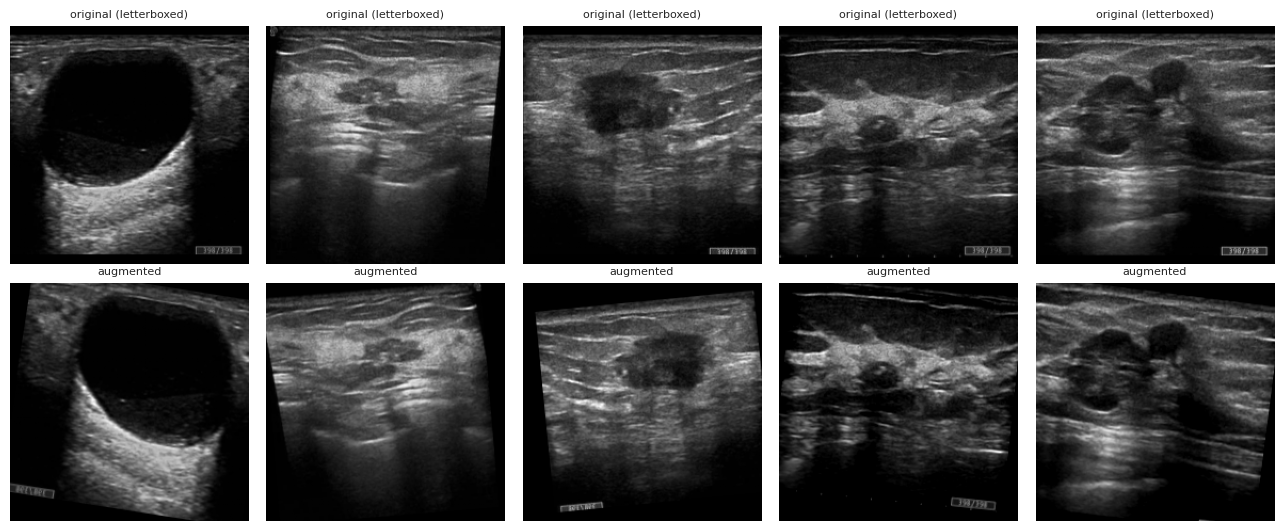

In [25]:
# ---- augmentation preview ------------------------------------------------
ds = BUSIData(train_idx, True)
fig, ax = plt.subplots(2, 5, figsize=(13, 5.4))
for j in range(5):
    ax[0, j].imshow(X_all[train_idx[j]], cmap='gray'); ax[0, j].set_title('original (letterboxed)', fontsize=8); ax[0, j].axis('off')
    xa = (ds[j][0] * STD + MEAN)[0].numpy(); ax[1, j].imshow(xa, cmap='gray'); ax[1, j].set_title('augmented', fontsize=8); ax[1, j].axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'T2_augmentation_preview.png', dpi=140); plt.show()

## 4. Training and evaluation helpers

In [29]:
# ---- 4. TRAINING / EVALUATION HELPERS -------------------------------------
@torch.no_grad()
def predict(model, dl):
    model.eval(); P, Y = [], []
    for xb, yb in dl:
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            out = model(xb.to(DEVICE, non_blocking=True))
        P.append(torch.softmax(out.float(), 1).cpu().numpy()); Y.append(yb.numpy())
    return np.concatenate(P), np.concatenate(Y)

def train_model(model, name, lr=1e-4, new_params=None, new_lr=None, epochs=25, patience=6, seed=SEED, verbose=True):
    seed_everything(seed)
    model.to(DEVICE)
    if new_params:
        ids = {id(p) for p in new_params}
        base = [p for p in model.parameters() if id(p) not in ids]
        groups = [{'params': base, 'lr': lr}, {'params': new_params, 'lr': new_lr or lr}]
    else:
        groups = [{'params': model.parameters(), 'lr': lr}]
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=CLASS_W.to(DEVICE))
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best, best_state, bad, hist = -1, None, 0, []
    if DEVICE == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb)
        sched.step()
        vp, vy = predict(model, val_dl)
        vf1 = f1_score(vy, vp.argmax(1), average='macro')
        vloss = float(F.nll_loss(torch.log(torch.tensor(vp) + 1e-8), torch.tensor(vy), weight=CLASS_W))
        hist.append(dict(epoch=ep, train_loss=tl / (len(train_dl) * BS), val_loss=vloss, val_macro_f1=vf1))
        if vf1 > best: best, best_state, bad = vf1, copy.deepcopy(model.state_dict()), 0
        else: bad += 1
        if verbose: print(f'[{name}] epoch {ep:02d} | train loss {hist[-1]["train_loss"]:.4f} | val macro-F1 {vf1:.4f}' + ('  *' if bad == 0 else ''))
        if bad >= patience:
            if verbose: print(f'[{name}] early stop (best val macro-F1 {best:.4f})')
            break
    if DEVICE == 'cuda': torch.cuda.synchronize()
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), train_time

def evaluate(name, model, train_time, pretrained, verbose=True):
    t0 = time.time(); probs, y = predict(model, test_dl)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    infer_ms = (time.time() - t0) / len(y) * 1000
    pred = probs.argmax(1)
    rep = classification_report(y, pred, target_names=CLASSES, output_dict=True)
    n_par = sum(p.numel() for p in model.parameters())
    row = dict(model=name, pretrained=pretrained, accuracy=accuracy_score(y, pred),
               precision_macro=rep['macro avg']['precision'], recall_macro=rep['macro avg']['recall'],
               f1_macro=rep['macro avg']['f1-score'], f1_weighted=rep['weighted avg']['f1-score'],
               recall_benign=rep['benign']['recall'], recall_malignant=rep['malignant']['recall'],
               roc_auc=roc_auc_score(y, probs[:, 1]), pr_auc=average_precision_score(y, probs[:, 1]),
               train_time_s=train_time, params_M=n_par / 1e6, size_MB=n_par * 4 / 1e6, infer_ms_per_img=infer_ms)
    if verbose:
        print(f'\n=== {name}: test set ===')
        print(classification_report(y, pred, target_names=CLASSES, digits=3))
    return row, probs

SEEDS = [42, 7, 2024]
SUM_COLS = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'recall_benign', 'recall_malignant', 'roc_auc', 'pr_auc', 'best_val_f1']

def summarize(runs):
    """mean +- std over seeds for every model"""
    rows = []
    for n, g in runs.groupby('model', sort=False):
        r = {'model': n, 'n_seeds': len(g)}
        for c in SUM_COLS: r[c] = f'{g[c].mean():.3f} +- {g[c].std():.3f}'
        for c in ['train_time_s', 'params_M', 'size_MB', 'infer_ms_per_img']: r[c] = round(g[c].mean(), 2)
        rows.append(r)
    return pd.DataFrame(rows).set_index('model')

def build_torchvision(ctor, weights_enum, head_fn):
    """Build a pretrained torchvision model; fall back to random init if weights cannot be downloaded."""
    try:
        m, pre = ctor(weights=weights_enum.DEFAULT), True
    except Exception as e:
        print('  (could not download pretrained weights -> random init):', str(e)[:80])
        m, pre = ctor(weights=None), False
    return head_fn(m), pre

def plot_curves(names, probs_dict, y, fname, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    for n in names:
        fpr, tpr, _ = roc_curve(y, probs_dict[n][:, 1]); ax[0].plot(fpr, tpr, label=f'{n} (AUC {roc_auc_score(y, probs_dict[n][:, 1]):.3f})')
        pr, rc, _ = precision_recall_curve(y, probs_dict[n][:, 1]); ax[1].plot(rc, pr, label=f'{n} (AP {average_precision_score(y, probs_dict[n][:, 1]):.3f})')
    ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves (malignant = positive)')
    ax[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curves (malignant = positive)')
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.suptitle(title, y=1.02)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150, bbox_inches='tight'); plt.show()

def plot_confusions(names, probs_dict, y, fname):
    fig, ax = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.6), squeeze=False)
    for a, n in zip(ax[0], names):
        cm = confusion_matrix(y, probs_dict[n].argmax(1))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=a)
        a.set(title=n, xlabel='Predicted', ylabel='True')
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

def plot_history(hists, fname):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for n, h in hists.items():
        ax[0].plot(h.epoch, h.train_loss, label=n); ax[1].plot(h.epoch, h.val_macro_f1, label=n)
    ax[0].set(xlabel='Epoch', ylabel='Training loss', title='Training loss'); ax[1].set(xlabel='Epoch', ylabel='Validation macro-F1', title='Validation macro-F1')
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

## 5. Baseline models
Four CNN baselines: a small CNN trained from scratch, and ResNet50, DenseNet121 and EfficientNet-B0 fine-tuned from ImageNet weights. All use the same split, augmentation, class-weighted loss, optimiser and early stopping on validation macro-F1.

In [33]:
def conv_block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
class SimpleCNN(nn.Module):
    def __init__(self, ch=(32, 64, 128, 256), drop=0.4):
        super().__init__()
        self.features = nn.Sequential(conv_block(3, ch[0]), conv_block(ch[0], ch[1]), conv_block(ch[1], ch[2]), conv_block(ch[2], ch[3]))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop), nn.Linear(ch[3], 2))
    def forward(self, x): return self.head(self.features(x))

def make_baseline(name):
    if name == 'SimpleCNN': return SimpleCNN(), False
    if name == 'ResNet50':
        return build_torchvision(models.resnet50, models.ResNet50_Weights, lambda m: (setattr(m, 'fc', nn.Sequential(nn.Dropout(0.3), nn.Linear(2048, 2))), m)[1])
    if name == 'DenseNet121':
        return build_torchvision(models.densenet121, models.DenseNet121_Weights, lambda m: (setattr(m, 'classifier', nn.Sequential(nn.Dropout(0.3), nn.Linear(1024, 2))), m)[1])
    if name == 'EfficientNet-B0':
        return build_torchvision(models.efficientnet_b0, models.EfficientNet_B0_Weights, lambda m: (setattr(m, 'classifier', nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 2))), m)[1])

BASELINES = ['SimpleCNN', 'ResNet50', 'DenseNet121', 'EfficientNet-B0']
LR = {'SimpleCNN': 1e-3, 'ResNet50': 1e-4, 'DenseNet121': 1e-4, 'EfficientNet-B0': 3e-4}

## 6. Train and evaluate all baselines (3 seeds each)

In [35]:
runs, probs, hists = [], {}, {}
for name in BASELINES:
    for sd in SEEDS:
        model, pre = make_baseline(name)
        model, hist, tt = train_model(model, name, lr=LR[name], seed=sd, verbose=False)
        row, p = evaluate(name, model, tt, pre, verbose=(sd == SEEDS[0]))
        row.update(seed=sd, best_val_f1=hist.val_macro_f1.max(), epochs_run=len(hist)); runs.append(row)
        print(f'[{name}] seed {sd}: best val macro-F1 {row["best_val_f1"]:.3f} | test macro-F1 {row["f1_macro"]:.3f} | test ROC-AUC {row["roc_auc"]:.3f} | {len(hist)} epochs')
        if sd == SEEDS[0]:
            probs[name], hists[name] = p, hist; hist.to_csv(OUT_DIR / f'history_{name}.csv', index=False)
        del model; torch.cuda.empty_cache()
runs = pd.DataFrame(runs); runs.to_csv(OUT_DIR / 'baseline_runs.csv', index=False)
np.savez(OUT_DIR / 'baseline_test_probs.npz', y=y_test, **{k.replace('-', '_'): v for k, v in probs.items()})


=== SimpleCNN: test set ===
              precision    recall  f1-score   support

      benign      0.667     0.840     0.743       100
   malignant      0.304     0.143     0.194        49

    accuracy                          0.611       149
   macro avg      0.486     0.491     0.469       149
weighted avg      0.548     0.611     0.563       149

[SimpleCNN] seed 42: best val macro-F1 0.635 | test macro-F1 0.469 | test ROC-AUC 0.497 | 8 epochs
[SimpleCNN] seed 7: best val macro-F1 0.609 | test macro-F1 0.562 | test ROC-AUC 0.602 | 10 epochs
[SimpleCNN] seed 2024: best val macro-F1 0.736 | test macro-F1 0.586 | test ROC-AUC 0.674 | 16 epochs
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 206MB/s]



=== ResNet50: test set ===
              precision    recall  f1-score   support

      benign      0.867     0.850     0.859       100
   malignant      0.706     0.735     0.720        49

    accuracy                          0.812       149
   macro avg      0.787     0.792     0.789       149
weighted avg      0.814     0.812     0.813       149

[ResNet50] seed 42: best val macro-F1 0.826 | test macro-F1 0.789 | test ROC-AUC 0.839 | 18 epochs
[ResNet50] seed 7: best val macro-F1 0.838 | test macro-F1 0.769 | test ROC-AUC 0.816 | 25 epochs
[ResNet50] seed 2024: best val macro-F1 0.828 | test macro-F1 0.720 | test ROC-AUC 0.804 | 13 epochs
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 242MB/s]



=== DenseNet121: test set ===
              precision    recall  f1-score   support

      benign      0.841     0.740     0.787       100
   malignant      0.574     0.714     0.636        49

    accuracy                          0.732       149
   macro avg      0.707     0.727     0.712       149
weighted avg      0.753     0.732     0.738       149

[DenseNet121] seed 42: best val macro-F1 0.849 | test macro-F1 0.712 | test ROC-AUC 0.811 | 23 epochs
[DenseNet121] seed 7: best val macro-F1 0.822 | test macro-F1 0.757 | test ROC-AUC 0.814 | 19 epochs
[DenseNet121] seed 2024: best val macro-F1 0.789 | test macro-F1 0.681 | test ROC-AUC 0.771 | 11 epochs
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 217MB/s]



=== EfficientNet-B0: test set ===
              precision    recall  f1-score   support

      benign      0.851     0.800     0.825       100
   malignant      0.636     0.714     0.673        49

    accuracy                          0.772       149
   macro avg      0.744     0.757     0.749       149
weighted avg      0.780     0.772     0.775       149

[EfficientNet-B0] seed 42: best val macro-F1 0.870 | test macro-F1 0.749 | test ROC-AUC 0.794 | 25 epochs
[EfficientNet-B0] seed 7: best val macro-F1 0.841 | test macro-F1 0.763 | test ROC-AUC 0.842 | 24 epochs
[EfficientNet-B0] seed 2024: best val macro-F1 0.846 | test macro-F1 0.729 | test ROC-AUC 0.822 | 18 epochs


## 7. Baseline comparison table

In [38]:
res = runs.groupby('model', sort=False).mean(numeric_only=True).drop(columns='seed').reset_index()
res.to_csv(OUT_DIR / 'baseline_results.csv', index=False)
summ = summarize(runs); summ.to_csv(OUT_DIR / 'baseline_summary.csv'); display(summ)
best_baseline = runs.groupby('model').best_val_f1.mean().idxmax()
best_test = res.sort_values('f1_macro', ascending=False).iloc[0].model
print(f'Best baseline by mean validation macro-F1: {best_baseline}  |  by mean test macro-F1: {best_test}')
print('Seed-to-seed spread (std of test macro-F1):', runs.groupby('model', sort=False).f1_macro.std().round(3).to_dict())

,n_seeds,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,recall_benign,recall_malignant,roc_auc,pr_auc,best_val_f1,train_time_s,params_M,size_MB,infer_ms_per_img
model,,,,,,,,,,,,,,,
SimpleCNN,3,0.620 +- 0.034,0.549 +- 0.057,0.548 +- 0.050,0.539 +- 0.062,0.603 +- 0.041,0.757 +- 0.112,0.340 +- 0.185,0.591 +- 0.089,0.458 +- 0.110,0.660 +- 0.067,26.34,1.17,4.69,2.31
ResNet50,3,0.779 +- 0.037,0.755 +- 0.036,0.773 +- 0.031,0.760 +- 0.036,0.783 +- 0.035,0.790 +- 0.056,0.755 +- 0.035,0.820 +- 0.017,0.706 +- 0.018,0.830 +- 0.006,65.82,23.51,94.05,3.04
DenseNet121,3,0.740 +- 0.034,0.712 +- 0.037,0.727 +- 0.041,0.717 +- 0.038,0.745 +- 0.034,0.767 +- 0.031,0.687 +- 0.066,0.799 +- 0.024,0.697 +- 0.032,0.820 +- 0.030,74.57,6.96,27.82,3.44
EfficientNet-B0,3,0.774 +- 0.017,0.745 +- 0.019,0.750 +- 0.016,0.747 +- 0.017,0.775 +- 0.016,0.820 +- 0.026,0.680 +- 0.031,0.819 +- 0.024,0.728 +- 0.024,0.853 +- 0.015,60.52,4.01,16.04,2.55


Best baseline by mean validation macro-F1: EfficientNet-B0  |  by mean test macro-F1: ResNet50
Seed-to-seed spread (std of test macro-F1): {'SimpleCNN': 0.062, 'ResNet50': 0.036, 'DenseNet121': 0.038, 'EfficientNet-B0': 0.017}


## 8. Curves, confusion matrices, training history

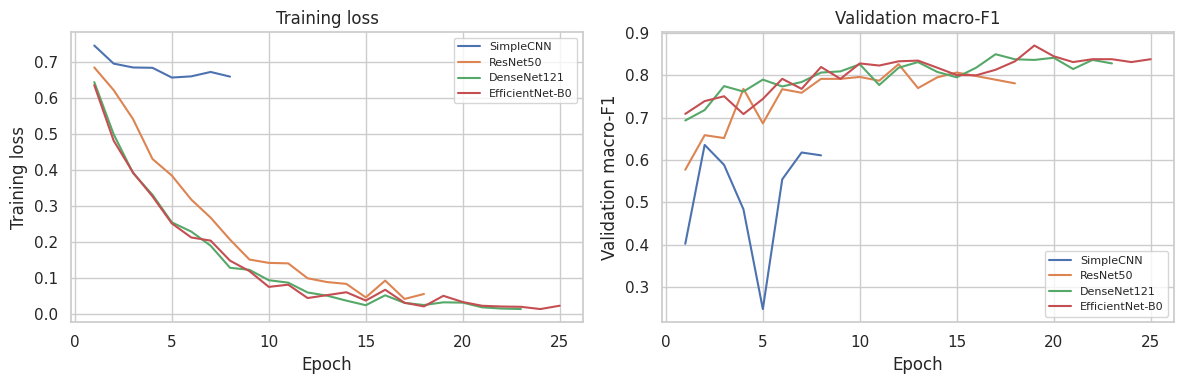

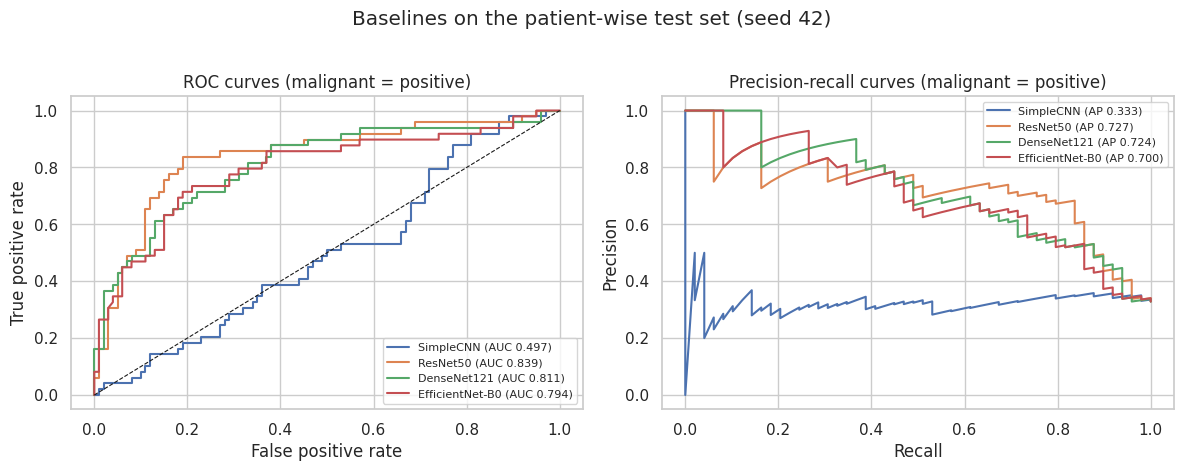

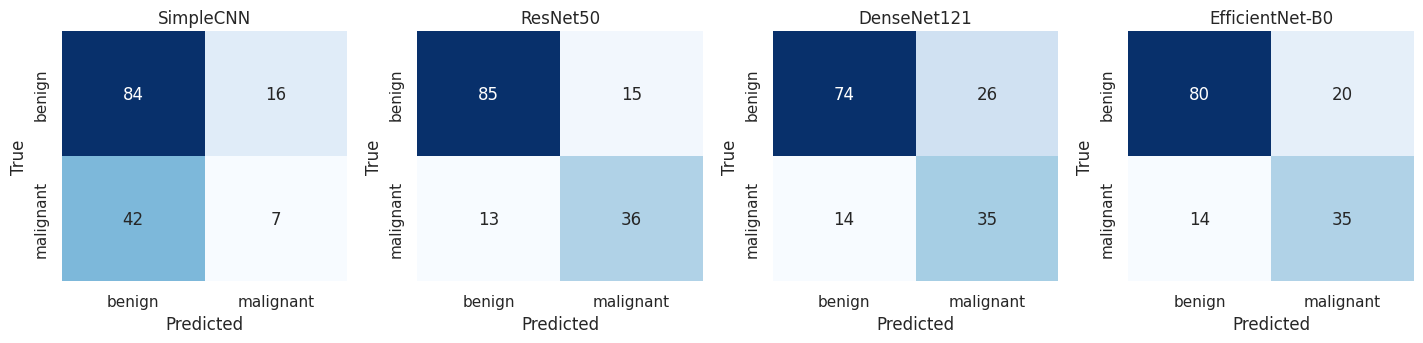

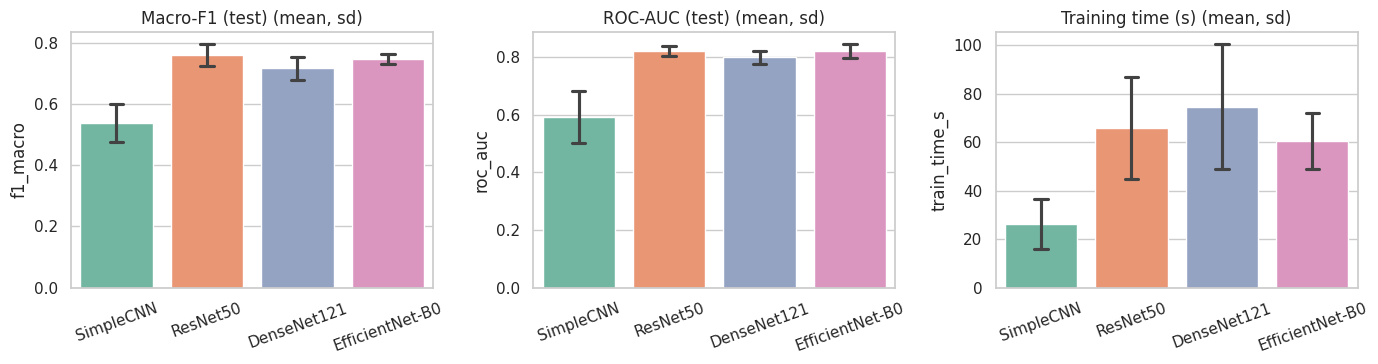

In [39]:
plot_history(hists, 'T2_baseline_training_history.png')
plot_curves(BASELINES, probs, y_test, 'T2_baseline_roc_pr.png', 'Baselines on the patient-wise test set (seed 42)')
plot_confusions(BASELINES, probs, y_test, 'T2_baseline_confusion.png')
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, col, t in zip(ax, ['f1_macro', 'roc_auc', 'train_time_s'], ['Macro-F1 (test)', 'ROC-AUC (test)', 'Training time (s)']):
    sns.barplot(x='model', y=col, data=runs, ax=a, palette='Set2', errorbar='sd', capsize=.15); a.set_title(t + ' (mean, sd)'); a.set_xlabel(''); a.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(OUT_DIR / 'T2_baseline_bars.png', dpi=150); plt.show()